In [48]:
# # Lab 3 — Millions of TVs, Who Is Watching?
# Name: Mykyta | Group: KM-42

import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/4")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
acr_sessions = pd.read_parquet(f"{DATA}/acr_sessions.parquet")
hh_attributes = pd.read_parquet(f"{DATA}/hh_attributes.parquet")
reference_ratings = pd.read_parquet(f"{DATA}/reference_ratings.parquet")









Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.


In [49]:
# ## Task 1.1 — Five questions
# **Answer:** the table (acr_sessions vs Lab 1 viewings) and the biggest difference.
# | Grain      | One TV session                       | One respondent viewing session     |
# | Key        | TV ID and session ID                 | viewing_id, respondent_id          |
# | Coverage   | Smart TV activity, including unknown | Panel household and person viewing |
# | Weight     | Unweighted, each TV counts once      | Weighted panel data                |
# | Provenance | Smart TV ACR technology              | Recruited TV audience panel        |
# Biggest difference is coverage
# ## Task 1.2 — Size and shape
# %%
acr = acr_sessions.copy()
acr["start_utc"] = pd.to_datetime(acr["start_utc"], utc=True)
acr["end_utc"] = pd.to_datetime(acr["end_utc"], utc=True)

acr["start_et"] = acr["start_utc"].dt.tz_convert("US/Eastern")
acr["end_et"] = acr["end_utc"].dt.tz_convert("US/Eastern")

acr["broadcast_day"] = (
    acr["start_et"] - pd.Timedelta(hours=6)
).dt.date

acr["duration_min"] = (
    acr["end_utc"] - acr["start_utc"]
).dt.total_seconds() / 60

acr_clean = acr[acr["duration_min"] >= 1].copy()

tv_count = acr["tv_id"].nunique()
session_count = len(acr)
day_count = acr["broadcast_day"].nunique()

tv_days = acr_clean[["tv_id", "broadcast_day"]].drop_duplicates()
in_tab_tv_days = len(tv_days)

avg_tvs = in_tab_tv_days / day_count

raw_hours = acr["duration_min"].sum() / 60
clean_hours = acr_clean["duration_min"].sum() / 60

hours_raw = raw_hours / in_tab_tv_days
hours_clean = clean_hours / in_tab_tv_days

dropped_share = (1 - len(acr_clean) / session_count) * 100

print("TVs:", tv_count)
print("Sessions:", session_count)
print("Broadcast days:", day_count)
print("Average TVs in-tab per day:", round(avg_tvs, 2))
print("Hours per TV per day, raw:", round(hours_raw, 2))
print("Hours per TV per day, after edit rule:", round(hours_clean, 2))
print("Share of sessions dropped:", round(dropped_share, 2), "%")


# ## Task 1.3 — What the TV could not see
# %%
... # table: share of hours by session_type and by input_source
total_hours = acr_clean["duration_min"].sum() / 60

unknown_hours = (
    acr_clean.loc[
        acr_clean["session_type"] == "unknown", "duration_min"
    ].sum() / 60
)
unknown_share = (unknown_hours / total_hours) * 100
print("Share of TV-on hours unknown (%):", round(unknown_share, 2))

# **Answer:** why a real feed may have more unknown; two kinds of viewing that end up unknown.
# steaming services and playstation or other device connected to tv

TVs: 29940
Sessions: 6392981
Broadcast days: 14
Average TVs in-tab per day: 29074.14
Hours per TV per day, raw: 4.74
Hours per TV per day, after edit rule: 4.7
Share of sessions dropped: 29.9 %
Share of TV-on hours unknown (%): 39.64


In [50]:

# ## Task 2.1 — Match
# %%
tvs = acr_sessions[["tv_id", "hashed_ip"]].drop_duplicates()

ip_households = (
    hh_attributes.groupby("hashed_ip")["household_id"]
    .nunique()
    .reset_index(name="household_count")
)

tvs = tvs.merge(ip_households, on="hashed_ip", how="left")

tvs["household_count"] = tvs["household_count"].fillna(0)

matched = tvs.loc[tvs["household_count"] == 1, "tv_id"].nunique()
shared = tvs.loc[tvs["household_count"] > 1, "tv_id"].nunique()
unmatched = tvs.loc[tvs["household_count"] == 0, "tv_id"].nunique()

total_tvs = tvs["tv_id"].nunique()

print("Matched to one household (%):", round(matched / total_tvs * 100, 2))
print("Shared IP, unresolved (%):", round(shared / total_tvs * 100, 2))
print("Not matched (%):", round(unmatched / total_tvs * 100, 2))

# **Answer:** why an IP address is a weak key.
"""
Why IP matching is hard
Household IP addresses rotate
Apartment buildings share one external IP across many
homes
Data providers report about 3.2 IPs per address; ISP
records show 1.2
"""



Matched to one household (%): 65.25
Shared IP, unresolved (%): 11.84
Not matched (%): 22.91


' \nWhy IP matching is hard\nHousehold IP addresses rotate\nApartment buildings share one external IP across many\nhomes\nData providers report about 3.2 IPs per address; ISP\nrecords show 1.2\n'

In [51]:
# ## Task 2.2 — Profile
# %%
matched_tvs = tvs[tvs["household_count"] == 1].merge(
    hh_attributes[["hashed_ip", "household_id", "region", "income_band"]],
    on="hashed_ip",
    how="inner"
)

def income_group(value):
    value = str(value).strip()

    if value in ["<$25k", "$25k-$50k"]:
        return "Under $50k"
    elif value in ["$50k-$75k", "$75k-$100k"]:
        return "$50-100k"
    elif value in ["$100k-$150k", "$150k+"]:
        return "$100k+"
    return None

matched_tvs["income_group"] = matched_tvs["income_band"].apply(income_group)

weights = daily_weights.copy()
weights["broadcast_date"] = pd.to_datetime(weights["broadcast_date"])

weights = weights[
    (weights["resp_type"] == "H") &
    (weights["broadcast_date"].between("2024-10-14", "2024-10-27"))
]

panel_weights = (
    weights.groupby("respondent_id")["weight"]
    .mean()
    .reset_index()
    .rename(columns={
        "respondent_id": "household_id",
        "weight": "avg_weight"
    })
)

panel = hh_attributes.merge(
    panel_weights,
    on="household_id",
    how="inner"
)

panel["income_group"] = panel["income_band"].apply(income_group)


def profile_table(column):
    footprint = matched_tvs.groupby(column)["tv_id"].nunique()
    footprint = footprint / footprint.sum() * 100

    panel_share = panel.groupby(column)["avg_weight"].sum()
    panel_share = panel_share / panel_share.sum() * 100

    result = pd.DataFrame({
        "Footprint share (%)": footprint,
        "Panel share (%)": panel_share
    }).fillna(0)

    result["Index"] = (
        result["Footprint share (%)"] /
        result["Panel share (%)"].replace(0, float("nan")) * 100
    )

    return result.round(2)

print("Profile by region:")
print(profile_table("region"))

print("\nProfile by income:")
print(profile_table("income_group"))
# table: group, footprint share, panel share, index (region and income)

# **Answer:** which groups are over/under-represented, and one reason.


Profile by region:
           Footprint share (%)  Panel share (%)   Index
region                                                 
Midwest                  20.15             0.00     NaN
Northeast                14.95            14.68  101.84
South                    38.30            28.61  133.88
West                     26.60            56.71   46.90

Profile by income:
              Footprint share (%)  Panel share (%)   Index
income_group                                              
$100k+                      47.63            43.03  110.67
$50-100k                    36.23            28.61  126.63
Under $50k                  16.14            28.36   56.93


In [52]:
# ## Task 2.3 — Ratings
# %%
# table: telecast, TVs' HH rating, reference HH rating
telecasts_23 = programs.merge(
    reference_ratings[["telecast_id", "hh_rating"]],
    on="telecast_id",
    how="inner"
).copy()

telecasts_23["start_ts"] = pd.to_datetime(
    telecasts_23["start_ts"], utc=True
)
telecasts_23["end_ts"] = pd.to_datetime(
    telecasts_23["end_ts"], utc=True
)

telecasts_23["broadcast_day"] = (
    telecasts_23["start_ts"].dt.tz_convert("US/Eastern")
    - pd.Timedelta(hours=6)
).dt.date

# TVs in-tab per broadcast day
tv_counts = (
    acr_clean.groupby("broadcast_day")["tv_id"]
    .nunique()
    .rename("in_tab_tvs")
)

telecasts_23 = telecasts_23.join(
    tv_counts, on="broadcast_day"
)

# Prepare live sessions
live = acr_clean[
    acr_clean["session_type"] == "live"
].copy()

live["start_utc"] = pd.to_datetime(
    live["start_utc"], utc=True
)
live["end_utc"] = pd.to_datetime(
    live["end_utc"], utc=True
)

# Calculate rating for each telecast
ratings = []

for _, t in telecasts_23.iterrows():

    sessions = live[
        (live["network_code"] == t["network_code"]) &
        (live["start_utc"] < t["end_ts"]) &
        (live["end_utc"] > t["start_ts"])
    ]

    overlap_start = sessions["start_utc"].clip(
        lower=t["start_ts"]
    )
    overlap_end = sessions["end_utc"].clip(
        upper=t["end_ts"]
    )

    overlap_minutes = (
        overlap_end - overlap_start
    ).dt.total_seconds() / 60

    watching_tvs = sessions.loc[
        overlap_minutes >= 1, "tv_id"
    ].nunique()

    rating = (
        watching_tvs / t["in_tab_tvs"] * 100
        if pd.notna(t["in_tab_tvs"]) and t["in_tab_tvs"] > 0
        else np.nan
    )

    ratings.append(rating)

telecasts_23["TVs HH rating"] = ratings

comparison = telecasts_23.rename(
    columns={"hh_rating": "Reference HH rating"}
).copy()

comparison["Ratio"] = (
    comparison["TVs HH rating"] /
    comparison["Reference HH rating"].replace(0, np.nan)
)

comparison["Difference"] = (
    comparison["TVs HH rating"] -
    comparison["Reference HH rating"]
)

comparison["Absolute difference"] = (
    comparison["Difference"].abs()
)

result = comparison[
    [
        "program_name",
        "broadcast_day",
        "TVs HH rating",
        "Reference HH rating",
        "Ratio"
    ]
].copy()

print("Ratings comparison:")
print(result.round(3).to_string(index=False))

print("\nAverage ratio:", round(comparison["Ratio"].mean(), 3))

print(
    "TV ratings too high:",
    (comparison["Difference"] > 0).sum()
)

print(
    "TV ratings too low:",
    (comparison["Difference"] < 0).sum()
)

valid = comparison.dropna(
    subset=["Absolute difference"]
)

print("\nFurthest off:")
print(
    valid.nlargest(5, "Absolute difference")[
        ["program_name", "broadcast_day", "Difference"]
    ].round(3).to_string(index=False)
)

print("\nClosest:")
print(
    valid.nsmallest(5, "Absolute difference")[
        ["program_name", "broadcast_day", "Difference"]
    ].round(3).to_string(index=False)
)

Ratings comparison:
                        program_name broadcast_day  TVs HH rating  Reference HH rating  Ratio
The Real Housewives of New York City    2024-10-15          0.167                 1.23  0.136
                                NCIS    2024-10-14          0.698                10.56  0.066
                             Hannity    2024-10-16          0.949                 2.30  0.412
       Halloween Baking Championship    2024-10-14          0.284                 1.63  0.174
                      MLB Postseason    2024-10-25          3.150                25.86  0.122
                        Grotesquerie    2024-10-16          0.735                 3.53  0.208
                   Unsellable Houses    2024-10-16          0.294                 3.69  0.080
                        NFL Football    2024-10-27          6.279                33.14  0.189

Average ratio: 0.173
TV ratings too high: 0
TV ratings too low: 8

Furthest off:
     program_name broadcast_day  Difference
     NFL

In [53]:
# ## Task 3.1 — Hours per home
# %%

networks = programs["network_code"].dropna().unique()

acr_live = acr_clean[
    (acr_clean["session_type"] == "live") &
    (acr_clean["network_code"].isin(networks))
].copy()

tv_live_hours = acr_live["duration_min"].sum() / 60

tv_days = acr_clean[
    ["tv_id", "broadcast_day"]
].drop_duplicates()

tv_hours_per_day = tv_live_hours / len(tv_days)

panel = viewings[
    (viewings["resp_type"] == "H") &
    (viewings["network_code"].isin(networks)) &
    (viewings["playback"] == "Live")
].copy()

panel["start_ts"] = pd.to_datetime(panel["start_ts"], utc=True)
panel["end_ts"] = pd.to_datetime(panel["end_ts"], utc=True)

panel["duration_hours"] = (
    panel["end_ts"] - panel["start_ts"]
).dt.total_seconds() / 3600

panel["broadcast_day"] = (
    panel["start_ts"].dt.tz_convert("US/Eastern")
    - pd.Timedelta(hours=6)
).dt.date

weights = daily_weights[
    daily_weights["resp_type"] == "H"
].copy()

weights["broadcast_day"] = pd.to_datetime(
    weights["broadcast_date"]
).dt.date

start_date = pd.to_datetime("2024-10-14").date()
end_date = pd.to_datetime("2024-10-27").date()

panel = panel[
    panel["broadcast_day"].between(start_date, end_date)
]

weights = weights[
    weights["broadcast_day"].between(start_date, end_date)
]

panel = panel.merge(
    weights[["respondent_id", "broadcast_day", "weight"]],
    on=["respondent_id", "broadcast_day"],
    how="inner",
    suffixes=("", "_daily")
)


weighted_hours = (
    panel["duration_hours"] * panel["weight_daily"]
).sum()


weighted_hh_days = weights["weight"].sum()

panel_hours_per_day = weighted_hours / weighted_hh_days

print("Live hours per TV per day (ten networks):",
      round(tv_hours_per_day, 3))

print("Live hours per panel household per day (ten networks):",
      round(panel_hours_per_day, 3))

# **Answer:** which is lower and why.


Live hours per TV per day (ten networks): 0.866
Live hours per panel household per day (ten networks): 1.911


In [54]:
# ## Task 3.2 — Network shares
# %%

tv_hours = (
    acr_live.groupby("network_code")["duration_min"]
    .sum() / 60
)

tv_share = tv_hours / tv_hours.sum() * 100

panel["weighted_hours"] = (
    panel["duration_hours"] * panel["weight_daily"]
)

panel_hours = (
    panel.groupby("network_code")["weighted_hours"]
    .sum()
)

panel_share = panel_hours / panel_hours.sum() * 100


network_comparison = pd.DataFrame({
    "TV share (%)": tv_share,
    "Panel share (%)": panel_share
}).fillna(0)


network_comparison["Difference (pp)"] = (
    network_comparison["TV share (%)"]
    - network_comparison["Panel share (%)"]
)


network_comparison["Status"] = network_comparison[
    "Difference (pp)"
].apply(
    lambda x: "Overstated" if x > 0
    else "Understated" if x < 0
    else "Equal"
)

network_comparison.index.name = "Network"


print("\nNetwork shares:")
print(network_comparison.round(2).to_string())


print("\nOverstated networks:")
print(
    network_comparison[
        network_comparison["Difference (pp)"] > 0
    ].index.tolist()
)


print("\nUnderstated networks:")
print(
    network_comparison[
        network_comparison["Difference (pp)"] < 0
    ].index.tolist()
)


Network shares:
         TV share (%)  Panel share (%)  Difference (pp)       Status
Network                                                             
ABC             19.59            18.67             0.92   Overstated
BRAVO            1.63             1.33             0.30   Overstated
CBS             18.22            19.65            -1.44  Understated
FNC              8.48            10.99            -2.50  Understated
FOOD             2.41             2.21             0.20   Overstated
FOX             20.15            19.39             0.76   Overstated
FX               2.79             2.16             0.63   Overstated
HGTV             3.41             3.09             0.32   Overstated
HIST             1.94             1.87             0.07   Overstated
NBC             21.38            20.64             0.74   Overstated

Overstated networks:
['ABC', 'BRAVO', 'FOOD', 'FOX', 'FX', 'HGTV', 'HIST', 'NBC']

Understated networks:
['CBS', 'FNC']


In [55]:
# ## Task 3.3 — What each can see
# **Answer:** two or three things each way.
"""
Panel Yes ACR not
1Household and personal viewings
2Population estimates

Panel No ACR Yes
1All TV activity
2More viewing patterns from TVs
3Can know where activity comes from
"""

' \nPanel Yes ACR not \n1Household and personal viewings\n2Population estimates\n\nPanel No ACR Yes \n1All TV activity\n2More viewing patterns from TVs\n3Can know where activity comes from \n'

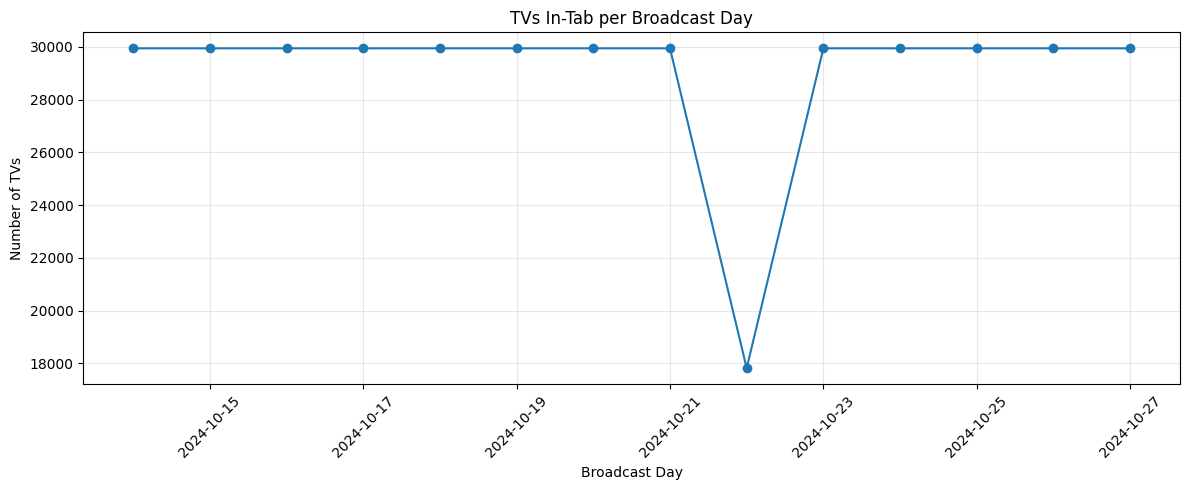

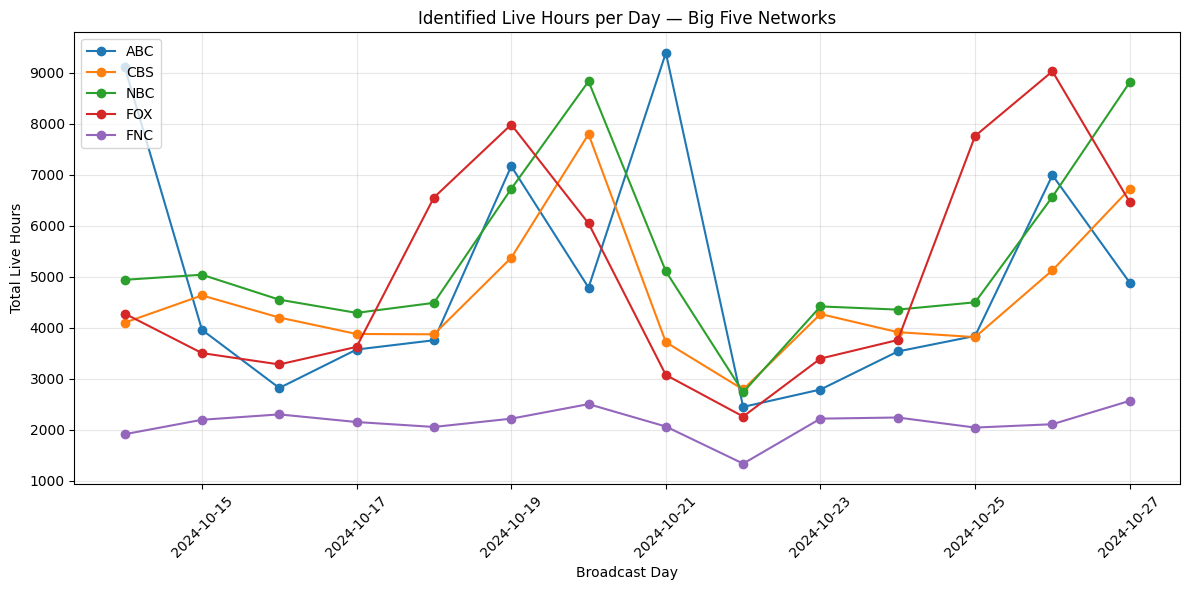

In [56]:
# ## Task 4.1 — Daily plots
# %%
... # plot: TVs in-tab per day; live hours per day for the big five networks
start_date = pd.to_datetime("2024-10-14").date()
end_date = pd.to_datetime("2024-10-27").date()

acr_2weeks = acr_clean[
    acr_clean["broadcast_day"].between(start_date, end_date)
].copy()

daily_tvs = (
    acr_2weeks.groupby("broadcast_day")["tv_id"]
    .nunique()
)

big_five = ["ABC", "CBS", "NBC", "FOX", "FNC"]

live_five = acr_2weeks[
    (acr_2weeks["session_type"] == "live") &
    (acr_2weeks["network_code"].isin(big_five))
].copy()

daily_hours = (
    live_five.groupby(["broadcast_day", "network_code"])["duration_min"]
    .sum()
    .div(60)
    .unstack(fill_value=0)
)

days = pd.date_range(start_date, end_date, freq="D")

daily_tvs.index = pd.to_datetime(daily_tvs.index)
daily_hours.index = pd.to_datetime(daily_hours.index)

daily_tvs = daily_tvs.reindex(days, fill_value=0)
daily_hours = daily_hours.reindex(
    index=days, columns=big_five, fill_value=0
)

plt.figure(figsize=(12, 5))

plt.plot(daily_tvs.index, daily_tvs.values, marker="o")

plt.title("TVs In-Tab per Broadcast Day")
plt.xlabel("Broadcast Day")
plt.ylabel("Number of TVs")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plot 2: Live hours by network
plt.figure(figsize=(12, 6))

for network in big_five:
    plt.plot(
        daily_hours.index,
        daily_hours[network],
        marker="o",
        label=network
    )

plt.title("Identified Live Hours per Day — Big Five Networks")
plt.xlabel("Broadcast Day")
plt.ylabel("Total Live Hours")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



In [57]:
# ## Task 4.2 — Spike and broken day
# %%

spike_date, spike_network = daily_hours.stack().idxmax()

print("Biggest spike (date, network):",
      spike_date.date(), spike_network)

print("Live hours:",
      round(daily_hours.loc[spike_date, spike_network], 2))

programs_copy = programs.copy()

programs_copy["start_ts"] = pd.to_datetime(
    programs_copy["start_ts"], utc=True
)

programs_copy["broadcast_day"] = (
    programs_copy["start_ts"].dt.tz_convert("US/Eastern")
    - pd.Timedelta(hours=6)
).dt.date

spike_programs = programs_copy[
    (programs_copy["broadcast_day"] == spike_date.date()) &
    (programs_copy["network_code"] == spike_network)
]

print("\nPrograms aired on spike day:")
print(
    spike_programs[
        ["program_name", "episode_name", "duration_min"]
    ].to_string(index=False)
)

daily_change = daily_tvs.pct_change()

broken_date = daily_change.idxmin()

print("\nBroken day (date):", broken_date.date())

print("TVs in-tab on broken day:",
      daily_tvs.loc[broken_date])


daily_quality = acr_2weeks.groupby("broadcast_day").agg(
    TVs=("tv_id", "nunique"),
    Sessions=("tv_id", "size"),
    Total_minutes=("duration_min", "sum")
)

daily_quality["Total_hours"] = (
    daily_quality["Total_minutes"] / 60
)

daily_quality["Hours_per_TV"] = (
    daily_quality["Total_hours"] / daily_quality["TVs"]
)


# **Answer:** what aired; what went wrong with the data; drop, fix or flag?

Biggest spike (date, network): 2024-10-21 ABC
Live hours: 9392.46

Programs aired on spike day:
                          program_name                                                                         episode_name  duration_min
                              The View                                                                             Tim Walz            60
        Local / Syndicated Programming                                                                                 None            60
                                  GMA3                                                      Sec. Al Schmidt, Courtney Mason            60
                      General Hospital                                                                           Ep. #15573            60
        Local / Syndicated Programming                                                                                 None           210
ABC World News Tonight with David Muir                                      

In [58]:


# ## Task 5.1 — Sampling error vs bias
# %%
... # table: telecast, SE footprint, SE panel, TVs' rating - reference

names = ["Sunday Night Football", "Hannity", "Unsellable Houses"]

telecasts = programs[
    programs["program_name"].str.contains(
        "|".join(names), case=False, na=False
    )
].copy()

telecasts["start_ts"] = pd.to_datetime(telecasts["start_ts"], utc=True)
telecasts["end_ts"] = pd.to_datetime(telecasts["end_ts"], utc=True)

telecasts["broadcast_day"] = (
    telecasts["start_ts"].dt.tz_convert("US/Eastern")
    - pd.Timedelta(hours=6)
).dt.date


telecasts = telecasts.merge(
    reference_ratings[["telecast_id", "hh_rating"]],
    on="telecast_id",
    how="inner"
)


tv_counts = (
    acr_clean.groupby("broadcast_day")["tv_id"]
    .nunique()
    .rename("n_tvs")
)


panel = daily_weights[daily_weights["resp_type"] == "H"].copy()
panel["broadcast_day"] = pd.to_datetime(
    panel["broadcast_date"]
).dt.date

panel_counts = (
    panel.groupby("broadcast_day")["respondent_id"]
    .nunique()
    .rename("n_panel")
)

telecasts = telecasts.join(tv_counts, on="broadcast_day")
telecasts = telecasts.join(panel_counts, on="broadcast_day")


live = acr_clean[acr_clean["session_type"] == "live"].copy()

live["start_utc"] = pd.to_datetime(live["start_utc"], utc=True)
live["end_utc"] = pd.to_datetime(live["end_utc"], utc=True)

ratings = []

for _, t in telecasts.iterrows():
    sessions = live[
        (live["network_code"] == t["network_code"]) &
        (live["start_utc"] < t["end_ts"]) &
        (live["end_utc"] > t["start_ts"])
    ].copy()

    overlap_start = sessions["start_utc"].clip(lower=t["start_ts"])
    overlap_end = sessions["end_utc"].clip(upper=t["end_ts"])

    overlap_minutes = (
        overlap_end - overlap_start
    ).dt.total_seconds() / 60

    watching = sessions.loc[overlap_minutes >= 1, "tv_id"].nunique()

    tv_rating = watching / t["n_tvs"] * 100

    ratings.append(tv_rating)

telecasts["TVs rating"] = ratings


p = telecasts["hh_rating"] / 100

telecasts["SE footprint"] = (
    np.sqrt(p * (1 - p) / telecasts["n_tvs"]) * 100
)

telecasts["SE panel"] = (
    np.sqrt(p * (1 - p) / telecasts["n_panel"]) * 100
)

telecasts["TVs rating - reference"] = (
    telecasts["TVs rating"] - telecasts["hh_rating"]
)

result = telecasts[
    [
        "program_name",
        "broadcast_day",
        "SE footprint",
        "SE panel",
        "TVs rating - reference"
    ]
].copy()

print(result.round(3).to_string(index=False))
# **Answer:** which error is bigger, and does more data shrink it?


# ## Task 5.2 — Answer to the planner
# **Answer:** 5-7 sentences.
"""
I can give household TV rating based on live viewing from smart TV ACR fingerprint.
But I cannot provide person level ratings cause this is ACR not panel.
ACR cannot capture viewing on streaming apps or devices connected like playstation.
Homes that couldnt be matched are missing.
Before using it for planning I would need reliable household matching, data quality checks and demographic weighting
"""




     program_name broadcast_day  SE footprint  SE panel  TVs rating - reference
          Hannity    2024-10-16         0.087     0.241                  -1.351
Unsellable Houses    2024-10-16         0.109     0.303                  -3.396


'\nI can give household TV rating based on live viewing from smart TV ACR fingerprint. \nBut I cannot provide person level ratings cause this is ACR not panel.  \nACR cannot capture viewing on streaming apps or devices connected like playstation. \nHomes that couldnt be matched are missing. \nBefore using it for planning I would need reliable household matching, data quality checks and demographic weighting\n'

In [59]:
# ## Bonus
# %%
t = telecasts.iloc[0]

panel = viewings.copy()

panel["start_ts"] = pd.to_datetime(panel["start_ts"], utc=True)
panel["end_ts"] = pd.to_datetime(panel["end_ts"], utc=True)

panel = panel[
    (panel["network_code"] == t["network_code"]) &
    (panel["playback"] == "Live") &
    (panel["start_ts"] < t["end_ts"]) &
    (panel["end_ts"] > t["start_ts"])
].copy()

overlap_start = panel["start_ts"].clip(lower=t["start_ts"])
overlap_end = panel["end_ts"].clip(upper=t["end_ts"])

panel["overlap_min"] = (
    overlap_end - overlap_start
).dt.total_seconds() / 60

panel = panel[panel["overlap_min"] >= 1].copy()

age_ids = [325, 335, 350]

adults = viewer_attributes[
    viewer_attributes["attr_id"].isin(age_ids)
]["respondent_id"].unique()

weights = daily_weights.copy()
weights["broadcast_day"] = pd.to_datetime(
    weights["broadcast_date"]
).dt.date

weights = weights[
    weights["broadcast_day"] == t["broadcast_day"]
]

#Weighted A25–54 viewers (R and L)
persons = panel[
    panel["resp_type"].isin(["R", "L"]) &
    panel["respondent_id"].isin(adults)
][["respondent_id"]].drop_duplicates()

person_weights = weights[
    weights["resp_type"].isin(["R", "L"])
][["respondent_id", "weight"]]

persons = persons.merge(
    person_weights, on="respondent_id", how="inner"
)

weighted_persons = persons["weight"].sum()

#Weighted viewing households (H)
households = panel[
    panel["resp_type"] == "H"
][["respondent_id"]].drop_duplicates()

hh_weights = weights[
    weights["resp_type"] == "H"
][["respondent_id", "weight"]]

households = households.merge(
    hh_weights, on="respondent_id", how="inner"
)

weighted_households = households["weight"].sum()

vpvh = weighted_persons / weighted_households

us_tv_households = hh_weights["weight"].sum()

all_adults = weights[
    weights["resp_type"].isin(["R", "L"]) &
    weights["respondent_id"].isin(adults)
]

us_a2554_persons = all_adults["weight"].sum()

tv_rating = t["TVs rating"]

a2554_rating = (
    tv_rating *
    vpvh *
    (us_tv_households / us_a2554_persons)
)

print("VPVH A25-54:", round(vpvh, 3))
print("A25-54 rating (persons):", round(a2554_rating, 3))


# **Answer:** what this assumes.git

VPVH A25-54: 0.057
A25-54 rating (persons): 0.055
